
# 9. # 
Load the MNIST dataset (introduced in Chapter 3) and split it into a training
set and a test set (take the first 60,000 instances for training, and the remaining
10,000 for testing). Train a random forest classifier on the dataset and time how
long it takes, then evaluate the resulting model on the test set. Next, use PCA
to reduce the dataset’s dimensionality, with an explained variance ratio of 95%.
Train a new random forest classifier on the reduced dataset and see how long it
takes. Was training much faster? Next, evaluate the classifier on the test set. How
does it compare to the previous classifier? Try again with an SGDClassifier.
How much does PCA help now?



In [31]:
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
import time


In [32]:
mnist = fetch_openml('mnist_784', as_frame=False)
X_treino, y_treino = mnist.data[:60_000], mnist.target[:60_000]
X_teste, y_teste = mnist.data[60_000:], mnist.target[60_000:]

In [33]:
rfc = RandomForestClassifier(random_state=42, max_depth=10)
inicio_rfc_treino = time.perf_counter()
rfc.fit(X_treino, y_treino)
fim_rfc_treino = time.perf_counter()
tempo_total_rfc = fim_rfc_treino - inicio_rfc_treino
print(f"Tempo exato: {tempo_total_rfc:.6f} segundos.")

Tempo exato: 20.517869 segundos.


In [34]:
rfc_acc_treino = rfc.score(X_treino, y_treino)
rfc_acc_teste = rfc.score(X_teste, y_teste)
print(f'RandomForestClassifier:\nAcurácia Treino: {rfc_acc_treino:4f}\nAcurácia Teste: {rfc_acc_teste:4f}')


RandomForestClassifier:
Acurácia Treino: 0.965033
Acurácia Teste: 0.948500


In [35]:
rfc_pca = make_pipeline(PCA(.95), RandomForestClassifier(random_state=42, max_depth=10))
inicio_rfc_pca_treino = time.perf_counter()
rfc_pca.fit(X_treino, y_treino)
fim_rfc_pca_treino = time.perf_counter()
tempo_total_rfc_pca = fim_rfc_pca_treino - inicio_rfc_pca_treino


In [36]:
print(f"Tempo exato: {tempo_total_rfc_pca:.6f} segundos.")

Tempo exato: 75.393609 segundos.


In [37]:
rfc_pca_acc_treino = rfc_pca.score(X_treino, y_treino)
rfc_pca_acc_teste = rfc_pca.score(X_teste, y_teste)
print(f'RandomForestClassifier PCA:\nAcurácia Treino: {rfc_pca_acc_treino:4f}\nAcurácia Teste: {rfc_pca_acc_teste:4f}')

RandomForestClassifier PCA:
Acurácia Treino: 0.950567
Acurácia Teste: 0.918400


In [38]:
sgd = SGDClassifier(random_state=42)
inicio_sgd_treino = time.perf_counter()
sgd.fit(X_treino, y_treino)
fim_sgd_treino = time.perf_counter()
tempo_total_sgd = fim_sgd_treino-inicio_sgd_treino
print(f"Tempo exato: {tempo_total_sgd:.6f} segundos.")

Tempo exato: 147.774280 segundos.


In [39]:
sgd_acc_treino = sgd.score(X_treino, y_treino)
sgd_acc_teste = sgd.score(X_teste, y_teste)
print(f'SGD:\nAcurácia Treino: {sgd_acc_treino:4f}\nAcurácia Teste: {sgd_acc_teste:4f}')

SGD:
Acurácia Treino: 0.880767
Acurácia Teste: 0.874000


In [40]:
sgd_pca = make_pipeline(PCA(.95), SGDClassifier(random_state=42))
inicio_sgd_pca_treino = time.perf_counter()
sgd_pca.fit(X_treino, y_treino)
fim_sgd_pca_treino = time.perf_counter()
tempo_total_sgd_pca = fim_sgd_pca_treino - inicio_sgd_pca_treino
print(f"Tempo exato: {tempo_total_sgd_pca:.6f} segundos.")

Tempo exato: 27.817209 segundos.


In [41]:
sgd_pca_acc_treino = sgd_pca.score(X_treino, y_treino)
sgd_pca_acc_teste = sgd_pca.score(X_teste, y_teste)
print(f'SGD PCA:\nAcurácia Treino: {sgd_pca_acc_treino:4f}\nAcurácia Teste: {sgd_pca_acc_teste:4f}')

SGD PCA:
Acurácia Treino: 0.892900
Acurácia Teste: 0.895900


# 10. #
Use t-SNE to reduce the first 5,000 images of the MNIST dataset down to 2
dimensions and plot the result using Matplotlib. You can use a scatterplot using
10 different colors to represent each image’s target class. Alternatively, you can
replace each dot in the scatterplot with the corresponding instance’s class (a digit
from 0 to 9), or even plot scaled-down versions of the digit images themselves
(if you plot all digits the visualization will be too cluttered, so you should either
draw a random sample or plot an instance only if no other instance has already
been plotted at a close distance). You should get a nice visualization with well
separated clusters of digits. Try using other dimensionality reduction algorithms,
such as PCA, LLE, or MDS, and compare the resulting visualizations.

In [80]:
from sklearn.manifold import TSNE, MDS, LocallyLinearEmbedding
from sklearn.datasets import fetch_openml
from matplotlib.pyplot import subplots

In [44]:
mnist = fetch_openml('mnist_784', as_frame=False)
dados_plot = mnist.data[:5_000]

Text(0.5, 1.0, 'TSNE')

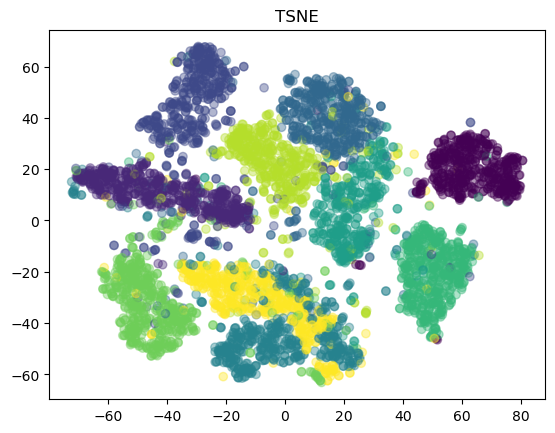

In [86]:
tsne = TSNE(n_components=2, random_state=42)
dados = tsne.fit_transform(dados_plot)
ax =subplots()[1]
ax.scatter(dados[:,0], dados[:,1], c=mnist.target[:5000].astype(int), alpha=0.4)
ax.set_title('TSNE')

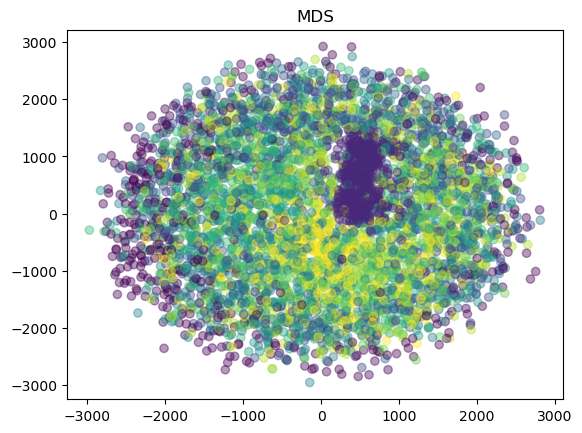

In [90]:
mds = MDS(n_components=2, n_init=4, max_iter=100, random_state=42)
dados = mds.fit_transform(dados_plot)
ax =subplots()[1]
ax.scatter(dados[:,0], dados[:,1], c=mnist.target[:5000].astype(int), alpha=0.4)
ax.set_title('MDS');

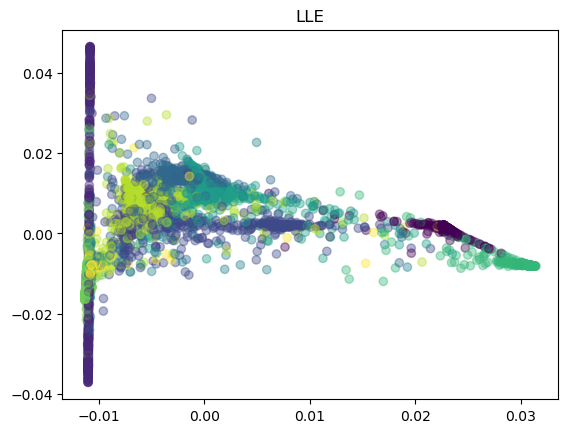

In [ ]:
lle = LocallyLinearEmbedding(n_components=2, random_state=42)
dados = lle.fit_transform(dados_plot)
ax =subplots()[1]
ax.scatter(dados[:,0], dados[:,1], c=mnist.target[:5000].astype(int), alpha=0.4)
ax.set_title('LLE');

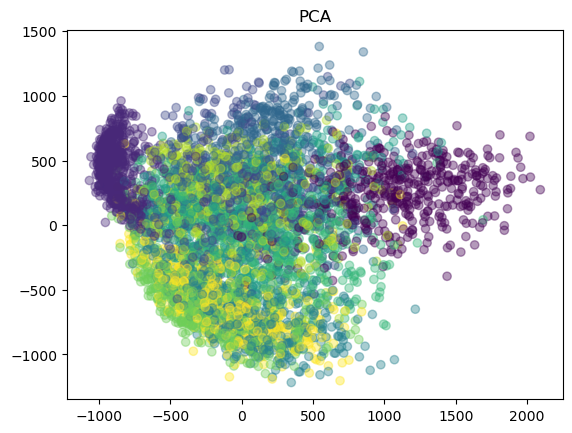

In [92]:
pca = PCA(n_components=2, random_state=42)
dados = pca.fit_transform(dados_plot)
ax =subplots()[1]
ax.scatter(dados[:,0], dados[:,1], c=mnist.target[:5000].astype(int), alpha=0.4)
ax.set_title('PCA');